In [ ]:
# Loading Geographic Data and Defining the Study Area:
# - Uses GeoPandas to load Iran's geographical boundary from a GeoJSON shapefile.
# - Defines the map extent covering Iran (25–40°N and 44–64°E).
# Defining the Visualization Settings:
# - Creates a custom blue-to-red colormap to represent different NO₂ column density values.
# - Sets the color range from zero to the 99.5th percentile of the NO₂ values, with an upper limit of \(1 \times 10^{-4}\) mol/m².
# Loading and Processing OMI Data:
# - Uses Xarray to read the monthly OMI NetCDF file containing OMNO2d_003_ColumnAmountNO2TropCloudScreened.
# - Calculates the temporal mean if a time dimension is available.
# - Converts NO₂ column density from molecules/cm² to mol/m² using Avogadro's constant and a unit conversion factor.
# - Clips negative values to zero to retain only non-negative NO₂ values.
# Spatial Masking and Map Preparation:
# - Creates a mask for the NO₂ dataset and applies it to the data.
# - Uses the geographical boundary of Iran to create a polygon representing areas outside the country.
# - Covers the areas outside Iran with white while retaining Iran's boundary.
# Generating and Saving the Map:
# - Uses Cartopy and Matplotlib to visualize the spatial distribution of monthly mean tropospheric NO₂ over Iran.
# - Adds Iran's borders, coastlines, and a vertical color bar with scientific notation.
# - Saves the final map as a high-resolution PNG image (output_no2_map.png) at 300 DPI.

محدوده رنگ: vmin=0, vmax=0.0001


C:\Users\intel\AppData\Local\Temp\ipykernel_6280\3453175036.py:54: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  [iran.unary_union],
C:\Users\intel\AppData\Local\Temp\ipykernel_6280\3453175036.py:82: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  outside_iran = world.difference(iran.unary_union)


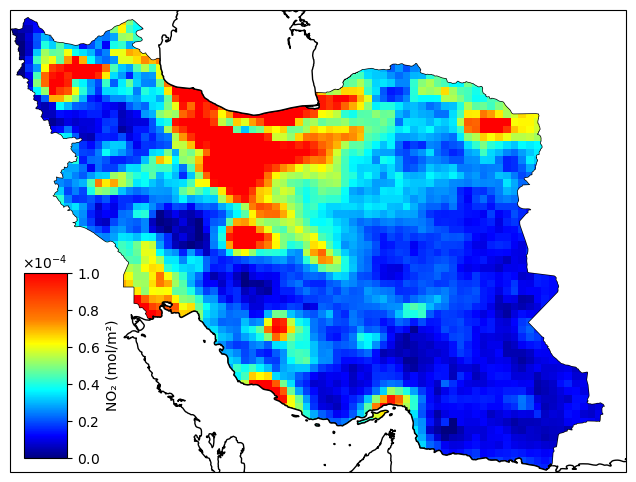

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import xarray as xr
import numpy as np
from shapely.geometry import box
from matplotlib.ticker import ScalarFormatter

# Function for determining the color range
def auto_color_range(da, lower_percentile=0, upper_percentile=99.5):
    lower = 0  # We always start from zero
    upper = float(da.quantile(upper_percentile / 100).values)
    return lower, upper

# Loading Iran shapefile
iran_shapefile = "C:/Users/intel/Documents/ir.json"
iran = gpd.read_file(iran_shapefile)

# Defining a custom colormap
colors = [
    (0.0, '#00007F'),
    (0.12, '#0000FF'),
    (0.37, '#00FFFF'),
    (0.62, '#FFFF00'),
    (0.75, '#FF7F00'),
    (1.0, '#FF0000')
]
custom_cmap = LinearSegmentedColormap.from_list("custom_no2", colors)

# Loading NO2 Data
ds = xr.open_dataset("C:/Users/intel/Documents/Omi/Monthly/g4.timeAvgMap.OMNO2d_003_ColumnAmountNO2TropCloudScreened.20240101-20240131.39E_23N_68E_42N.nc")
no2 = ds['OMNO2d_003_ColumnAmountNO2TropCloudScreened']

# Unit Conversion and Averaging
NA = 6.02214076e23  # Avogadro's Number
no2_mean = no2.mean(dim='time') if 'time' in no2.dims else no2
no2_mean_mol = (no2_mean / NA) * 1e4  # Conversion to mol/m²
no2_mean_mol = no2_mean_mol.clip(min=0)  # Ensuring non-negative values

# Defining the color range with a maximum of 1e-4
vmin = 0
vmax = min(float(no2_mean_mol.quantile(0.995).values), 1e-4)  # Maximum 1e-4
print(f"Color Range: vmin={vmin}, vmax={vmax}")

# Creating a Map
fig = plt.figure(figsize=(10, 6), facecolor='white')
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([44, 64, 25, 40], crs=ccrs.PlateCarree())

# The Correct Method for Whitening Outside the Borders
ax.add_geometries(
    [iran.unary_union],
    crs=ccrs.PlateCarree(),
    facecolor='none',
    edgecolor='black',
    linewidth=1
)

mask = xr.DataArray(
    data=np.ones_like(no2_mean_mol),
    dims=no2_mean_mol.dims,
    coords=no2_mean_mol.coords
)

no2_masked = no2_mean_mol.where(mask)

# Data Visualization
plot = no2_masked.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=custom_cmap,
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# Masking areas outside Iran with white color
bounds = ax.get_extent()
world = box(bounds[0], bounds[2], bounds[1], bounds[3])
outside_iran = world.difference(iran.unary_union)

ax.add_geometries(
    [outside_iran],
    crs=ccrs.PlateCarree(),
    facecolor='white',
    edgecolor='none'
)

# Map Features
ax.coastlines()

# Legend with scientific representation of numbers
cax = inset_axes(ax, width="7%", height="40%", loc='lower left', borderpad=1)
cbar = fig.colorbar(plot, cax=cax, orientation='vertical')
cbar.set_label("NO₂ (mol/m²)")

# Setting scientific format for the legend with a limit of 1e4
cbar.formatter = ScalarFormatter(useMathText=True)
cbar.formatter.set_powerlimits((0, 4))  # Scientific notation for numbers between 0 and 1e4
cbar.update_ticks()

# Save Map
plt.savefig("output_no2_map.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()